# Data import, preprocessing, and sequence visualization

This notebook reproduces the first step of pipeline described in: *"Enhancing comorbidity network inference with risk-enriched health trajectories embedding"*

**NOTE (Simulated data):** When `DATA_MODE = "simulated"`, the pipeline
runs on synthetic data generated by `simulate_sequences.py`. Simulated
patients do not represent real individuals. Network structures will differ
from the original publication results.

## Section 0 — Configuration

Set `DATA_MODE = "simulated"` to use the synthetic sequences generated by
`simulate_sequences.py` (run it first: `python simulate_sequences.py`).
Set `DATA_MODE = "real"` and fill in the paths below to use your own data.
The real-data files must have columns: `ID`, `age_in_days_since_born`, `event_name`.

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import networkx as nx
from scipy.spatial.distance import cosine
from scipy.stats import mannwhitneyu, pearsonr, spearmanr
from scipy.special import erfc
from sklearn.covariance import GraphicalLassoCV
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120})

# ── User configuration ────────────────────────────────────────────────────────
DATA_MODE = "simulated"   # "simulated" | "real"

# Paths for real data (only used when DATA_MODE = "real")
REAL_MAIN_SEQ_PATH     = None   #None e.g. "/path/to/sequence_main_final.csv"
REAL_PARALLEL_SEQ_PATH = None   #None e.g. "/path/to/sequence_parallel_final.csv"

# Output directories
OUTPUT_RES_DIR   = "results"
OUTPUT_PLOTS_DIR = "plots"
os.makedirs(OUTPUT_RES_DIR,   exist_ok=True)
os.makedirs(OUTPUT_PLOTS_DIR, exist_ok=True)

print(f"DATA_MODE = {DATA_MODE}")
print("Configuration loaded.")

## Section 1 — Data Import and Preprocessing

### 1.1  Load sequences

Simulated sequences are produced by `simulate_sequences.py`.
Both files share the same column schema:

| Column | Description |
|---|---|
| `ID` | Patient identifier |
| `age_in_days_since_born` | Age at event (days) |
| `event_name` | MeSH disease / risk-factor name |

In [35]:
if DATA_MODE == "simulated":
    MAIN_PATH     = os.path.join("data_simulated", "sequence_main_simulated.csv")
    PARALLEL_PATH = os.path.join("data_simulated", "sequence_parallel_simulated.csv")
else:
    MAIN_PATH     = REAL_MAIN_SEQ_PATH
    PARALLEL_PATH = REAL_PARALLEL_SEQ_PATH

df_main     = pd.read_csv(MAIN_PATH)
df_parallel = pd.read_csv(PARALLEL_PATH)

print(f"Main sequence:     {df_main.shape[0]:,} rows  |  {df_main['ID'].nunique():,} unique patients")
print(f"Parallel sequence: {df_parallel.shape[0]:,} rows  |  {df_parallel['ID'].nunique():,} unique patients")
df_main.head(3)


Main sequence:     35,637 rows  |  5,000 unique patients
Parallel sequence: 530,066 rows  |  5,000 unique patients


,ID,age_in_days_since_born,event_name
0,1,20976,Diabetes Mellitus
1,1,21997,Hypertension
2,1,28480,"Kidney Diseases, Chronic, Stage 3"


### 1.2  Filtering

* Remove events at age = 0 from the main sequence.
* Retain only patients with **≥ 3 distinct disease events** (mirrors the real-data cohort criterion).

In [36]:
# Remove age-0 entries from main sequence
df_main = df_main[df_main["age_in_days_since_born"] > 0].copy()

# Keep patients with ≥ 3 distinct disease events
counts   = df_main.groupby("ID")["event_name"].nunique()
keep_ids = counts[counts >= 3].index
df_main     = df_main[df_main["ID"].isin(keep_ids)].copy()
df_parallel = df_parallel[df_parallel["ID"].isin(keep_ids)].copy()

print(f"After filtering:")
print(f"  Main sequence:     {len(df_main):,} rows  |  {df_main['ID'].nunique():,} patients")
print(f"  Parallel sequence: {len(df_parallel):,} rows  |  {df_parallel['ID'].nunique():,} patients")

After filtering:
  Main sequence:     33,918 rows  |  4,492 patients
  Parallel sequence: 501,593 rows  |  4,492 patients


### 1.3  Build final sequence DataFrames

Save the processed sequences for downstream steps.

In [43]:
# Main-only events (sorted by patient and age)
sequence_main_final = (
    df_main
    .sort_values(["ID", "age_in_days_since_born"])
    .reset_index(drop=True)
)

sequence_par_final = (
    df_parallel
    .sort_values(["ID", "age_in_days_since_born"])
    .reset_index(drop=True)
)

# Main + parallel (concatenate and sort)
sequence_main_par_final = (
    pd.concat([sequence_main_final, df_parallel])
    .sort_values(["ID", "age_in_days_since_born"])
    .reset_index(drop=True)
)



sequence_main_final.to_csv(os.path.join(OUTPUT_RES_DIR,"sequence_main_final.csv"), index=False)
sequence_par_final.to_csv(os.path.join(OUTPUT_RES_DIR,"sequence_par_final.csv"), index=False)
sequence_main_par_final.to_csv(os.path.join(OUTPUT_RES_DIR,"sequence_main_par_final.csv"), index=False)

print(f"sequence_main_final:      {len(sequence_main_final):,} rows")
print(f"sequence_par_final:      {len(sequence_par_final):,} rows")
print(f"sequence_main_par_final: {len(sequence_main_par_final):,} rows")

sequence_main_final:      33,918 rows
sequence_par_final:      501,593 rows
sequence_main_par_final: 535,511 rows


### 1.5  Cohort summary statistics

In [40]:
n_patients = sequence_main_final["ID"].nunique()
data_unique = sequence_main_final.groupby(["ID", "event_name"], as_index=False).first()

incidence_df = (
    data_unique.groupby("event_name")["ID"].nunique()
    .reset_index(name="n_patients_with_disease")
    .assign(incidence_pct=lambda x: x["n_patients_with_disease"] / n_patients * 100)
    .sort_values("incidence_pct", ascending=False)
    .reset_index(drop=True)
)
print(f"Total patients: {n_patients:,}")
print(f"Total main-sequence events: {len(sequence_main_final):,}")
display(incidence_df.style.format({"incidence_pct": "{:.1f}%"}))

Total patients: 4,492
Total main-sequence events: 33,918


,event_name,n_patients_with_disease,incidence_pct
0,Hypertension,4373,97.4%
1,Dyslipidemias,3559,79.2%
2,Coronary Disease,2346,52.2%
3,Diabetes Mellitus,1826,40.7%
4,Atrial Fibrillation,1470,32.7%
5,Cerebrovascular Disorders,985,21.9%
6,Acute Kidney Injury,970,21.6%
7,"Kidney Diseases, Chronic, Stage 3",881,19.6%
8,Heart Failure,872,19.4%
9,"Pacemaker, Artificial",500,11.1%


### 1.6  Visualizations

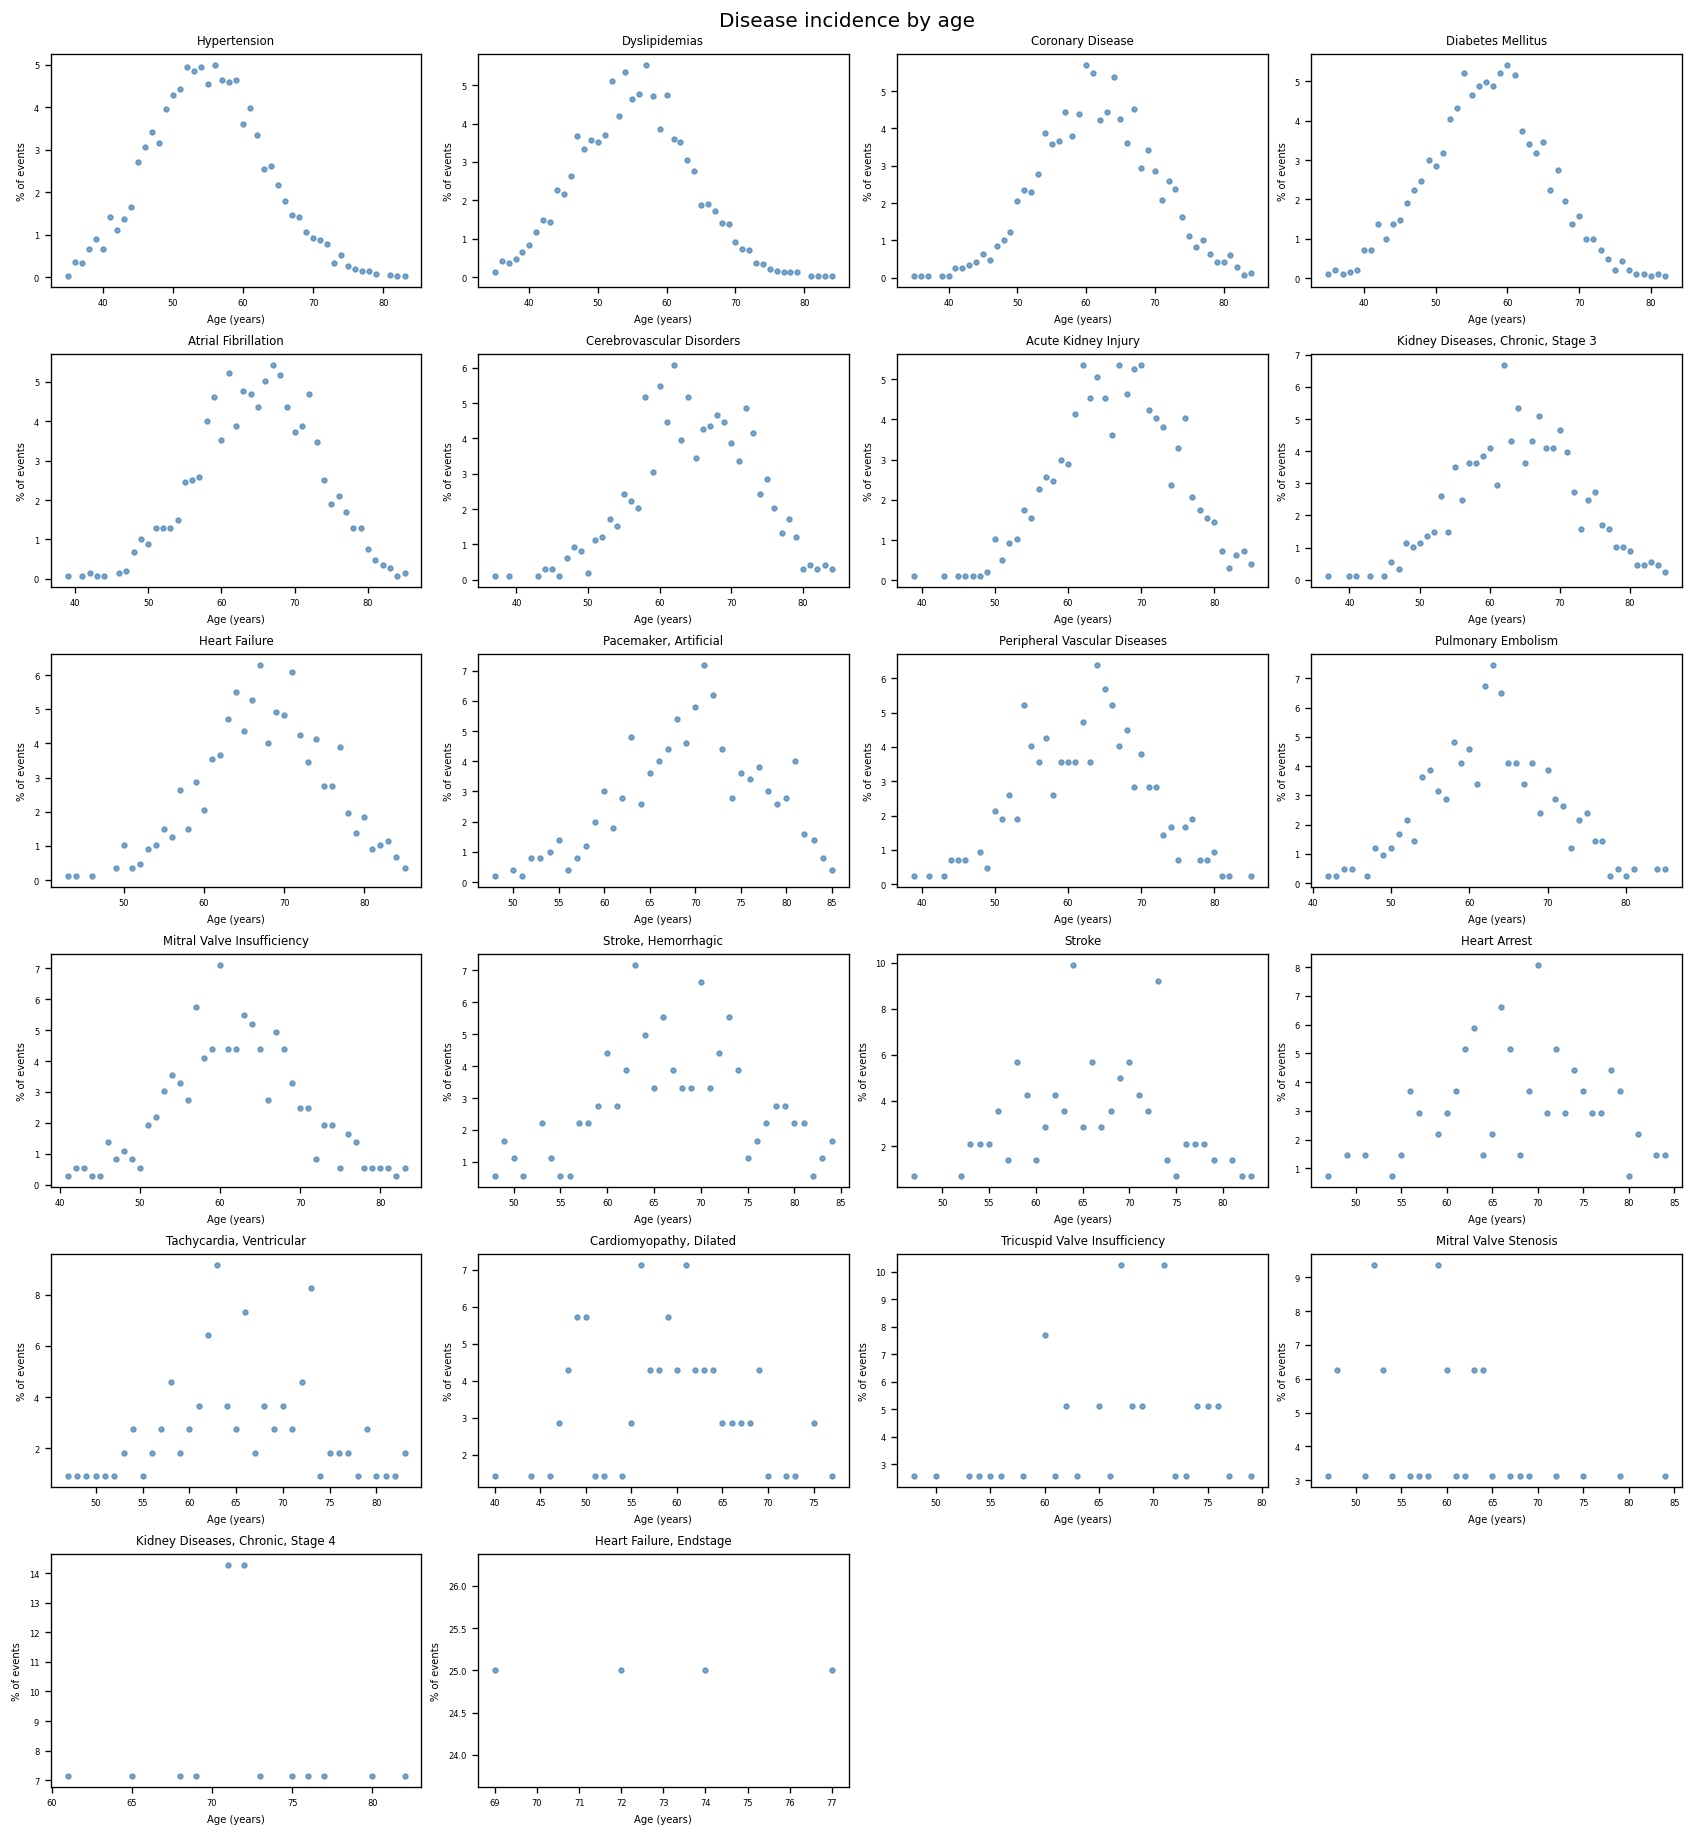

Saved: disease_incidence_by_age.png / .svg


In [41]:
# ── Plot 1: Disease incidence by age (6×4 faceted) ──────────────────────────
# First incidence per patient per disease, convert to years
first_incidence = (
    sequence_main_final
    .sort_values(["ID", "age_in_days_since_born"])
    .groupby(["ID", "event_name"], as_index=False)
    .first()
)
first_incidence["age_yr"] = np.round(
    first_incidence["age_in_days_since_born"] / 365
).astype(int)

age_dist = (
    first_incidence
    .groupby(["event_name", "age_yr"])
    .size()
    .reset_index(name="N")
)
total_per_disease = age_dist.groupby("event_name")["N"].sum().reset_index(name="total")
age_dist = age_dist.merge(total_per_disease, on="event_name")
age_dist["pct"] = age_dist["N"] / age_dist["total"] * 100

diseases_sorted = incidence_df["event_name"].tolist()
n_diseases = len(diseases_sorted)
ncols, nrows = 4, int(np.ceil(n_diseases / 4))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 2.5), constrained_layout=True)
axes = axes.flatten()

for ax, disease in zip(axes, diseases_sorted):
    sub = age_dist[age_dist["event_name"] == disease]
    ax.scatter(sub["age_yr"], sub["pct"], color="steelblue", s=8, alpha=0.7)
    ax.set_title(disease, fontsize=7, wrap=True)
    ax.set_xlabel("Age (years)", fontsize=6)
    ax.set_ylabel("% of events", fontsize=6)
    ax.tick_params(labelsize=5)

for ax in axes[n_diseases:]:
    ax.set_visible(False)

fig.suptitle("Disease incidence by age", fontsize=12, y=1.01)
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_incidence_by_age.png"),
            dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_incidence_by_age.svg"),
            format="svg", bbox_inches="tight")
plt.show()
print("Saved: disease_incidence_by_age.png / .svg")

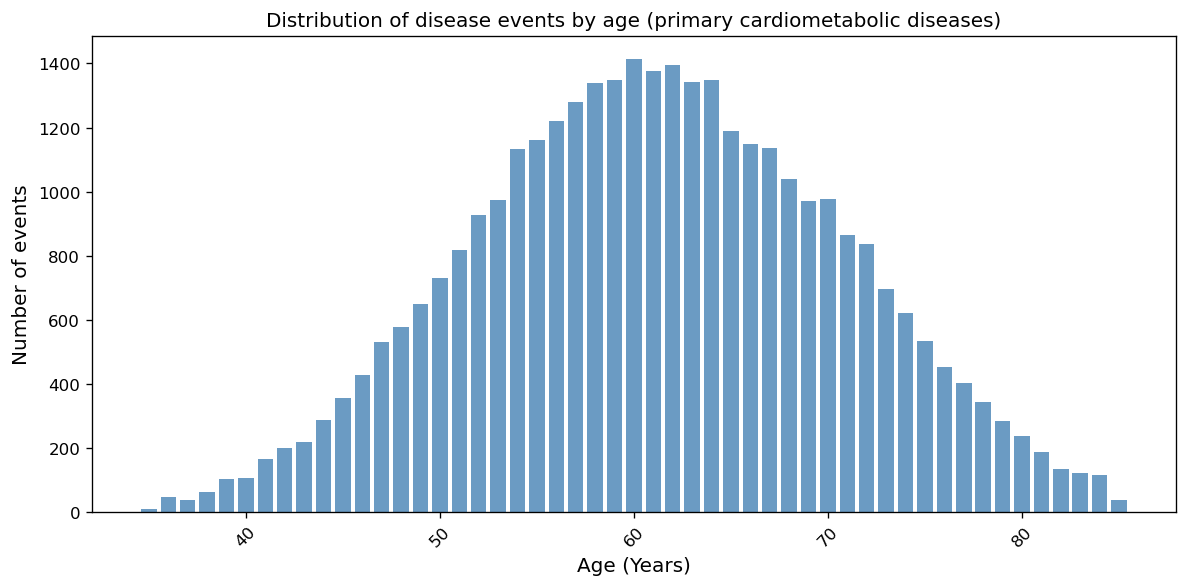

Saved: total_events_by_age.png / .svg


In [42]:
# ── Plot 2: Total disease events distribution by age ─────────────────────────
all_events_age = sequence_main_final.copy()
all_events_age["age_yr"] = np.round(
    all_events_age["age_in_days_since_born"] / 365
).astype(int)

total_by_age = all_events_age.groupby("age_yr").size().reset_index(name="N")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(total_by_age["age_yr"], total_by_age["N"], color="steelblue", alpha=0.8)
ax.set_xlabel("Age (Years)", fontsize=12)
ax.set_ylabel("Number of events", fontsize=12)
ax.set_title("Distribution of disease events by age (primary cardiometabolic diseases)",
             fontsize=12)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "total_events_by_age.png"),
            dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "total_events_by_age.svg"),
            format="svg", bbox_inches="tight")
plt.show()
print("Saved: total_events_by_age.png / .svg")